In [1]:
import kagglehub
dataset_path = kagglehub.dataset_download("chavidubandara/dairyfusion-ai-yoghurt-cup-defect-dataset")
print("dataset downloaded to:",dataset_path)

100%|██████████| 30.6M/30.6M [00:00<00:00, 79.0MB/s]

Extracting files...


dataset downloaded to: /root/.cache/kagglehub/datasets/chavidubandara/dairyfusion-ai-yoghurt-cup-defect-dataset/versions/1


In [3]:
import yaml
import glob
import os

yaml_files = glob.glob(f"{dataset_path}/**/data_balanced.yaml", recursive=True)
yaml_path = yaml_files[0]
base_dir = os.path.dirname(yaml_path)

with open(yaml_path, "r") as f:
    data_config = yaml.safe_load(f)

print("Original data.yaml contents:\n", data_config)

data_config["path"] = base_dir
with open(yaml_path, "w") as f:
    yaml.safe_dump(data_config, f)

print("\nUpdated data.yaml path to:", base_dir)

Original data.yaml contents:
 {'names': ['cup', 'dustparticle', 'eyelash', 'foam', 'hair', 'insect', 'overfill', 'plasticparticle', 'residue', 'underfill', 'waterbubble', 'waterlayer'], 'nc': 12, 'path': 'C:\\Users\\User\\Dairy-FusionAI-3 - model\\Dairy\\Dairy', 'train': 'train_balanced/images', 'val': 'val_balanced/images'}

Updated data.yaml path to: /root/.cache/kagglehub/datasets/chavidubandara/dairyfusion-ai-yoghurt-cup-defect-dataset/versions/1


In [10]:
import glob
import os
import cv2
import matplotlib.pyplot as plt
from collections import Counter

print("Dataset Splits:")
for split in ["train_balanced", "val_balanced", "test"]:
    imgs = glob.glob(f"{base_dir}/{split}/**/images/*.*", recursive=True)
    lbls = glob.glob(f"{base_dir}/{split}/**/labels/*.txt", recursive=True)
    print(f"  {split:<15} -> Images: {len(imgs)} | Labels: {len(lbls)}")

Dataset Splits:
  train_balanced  -> Images: 393 | Labels: 393
  val_balanced    -> Images: 69 | Labels: 69
  test            -> Images: 27 | Labels: 27


In [12]:
class_names = data_config["names"]
counts = Counter()
for lbl_file in glob.glob(f"{base_dir}/train_balanced/**/labels/*.txt", recursive=True):
    with open(lbl_file, "r") as f:
        for line in f:
            if line.strip():
              cls_id = int(line.split()[0])
              counts[cls_id] += 1

print("\nTraining Set Annotations per Class:")
for idx in range(len(class_names)):
    print(f"  Class {idx:2d} ({class_names[idx]:<15}): {counts[idx]}")


Training Set Annotations per Class:
  Class  0 (cup            ): 393
  Class  1 (dustparticle   ): 50
  Class  2 (eyelash        ): 30
  Class  3 (foam           ): 49
  Class  4 (hair           ): 39
  Class  5 (insect         ): 52
  Class  6 (overfill       ): 10
  Class  7 (plasticparticle): 76
  Class  8 (residue        ): 64
  Class  9 (underfill      ): 16
  Class 10 (waterbubble    ): 58
  Class 11 (waterlayer     ): 27


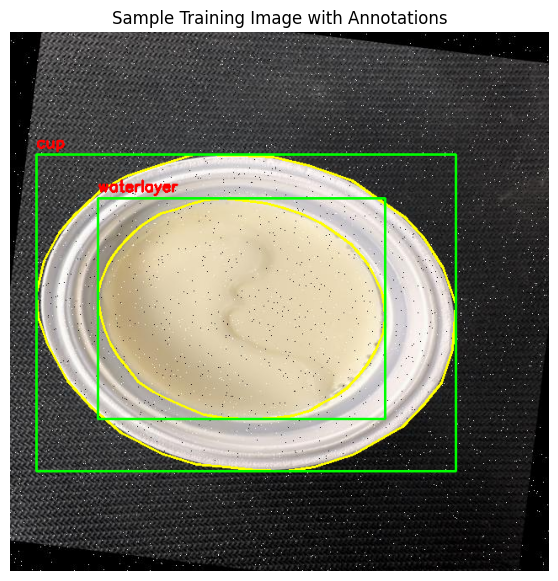

In [15]:
import numpy as np
sample_imgs = glob.glob(f"{base_dir}/train_balanced/**/images/*.*", recursive=True)
sample_img_path = sample_imgs.pop(0)
base_name, _ = os.path.splitext(sample_img_path)
sample_lbl_path = base_name.replace("/images/", "/labels/")+ ".txt"

img = cv2.cvtColor(cv2.imread(sample_img_path), cv2.COLOR_BGR2RGB)
h, w, _ = img.shape

with open(sample_lbl_path, "r") as f:
    for line in f:
      vals = list(map(float, line.strip().split()))
      if not vals:
            continue

      cls_id = int(vals.pop(0))

      if len(vals) == 4:
            xc, yc, bw, bh = vals
            x1, y1 = int((xc - bw / 2) * w), int((yc - bh / 2) * h)
            x2, y2 = int((xc + bw / 2) * w), int((yc + bh / 2) * h)
      else:
            xs = vals[0::2]
            ys = vals[1::2]
            x1, y1 = int(min(xs) * w), int(min(ys) * h)
            x2, y2 = int(max(xs) * w), int(max(ys) * h)


            pts = np.array([[int(x * w), int(y * h)] for x, y in zip(xs, ys)], np.int32)
            cv2.polylines(img, [pts], isClosed=True, color=(255, 255, 0), thickness=2)


      cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
      cv2.putText(img, class_names[cls_id], (x1, max(y1 - 8, 15)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)

plt.figure(figsize=(7, 7))
plt.imshow(img)
plt.title("Sample Training Image with Annotations")
plt.axis("off")
plt.show()


In [16]:
valid_pairs = 0
missing_labels = 0
invalid_coords = 0
resolutions = set()

for split in ["train_balanced", "val_balanced", "test"]:
    img_paths = glob.glob(f"{base_dir}/{split}/**/images/*.*", recursive=True)

    for img_path in img_paths:
        img = cv2.imread(img_path)
        if img is None:
            print(f"Corrupt image: {img_path}")
            continue
        resolutions.add(img.shape)

        base_name, _ = os.path.splitext(img_path)
        lbl_path = base_name.replace("/images/", "/labels/") + ".txt"

        if not os.path.exists(lbl_path):
            missing_labels += 1
            continue

        with open(lbl_path, "r") as f:
            for line in f:
                vals = list(map(float, line.strip().split()))
                if len(vals) < 5:
                    invalid_coords += 1
                elif any(v < 0.0 or v > 1.0 for v in vals[1:]):
                    invalid_coords += 1
        valid_pairs += 1

print(f"Valid Image-Label Pairs : {valid_pairs}")
print(f"Missing Label Files     : {missing_labels}")
print(f"Invalid Annotations     : {invalid_coords}")
print(f"Image Resolutions Found : {resolutions}")

Valid Image-Label Pairs : 489
Missing Label Files     : 0
Invalid Annotations     : 0
Image Resolutions Found : {(640, 640, 3)}


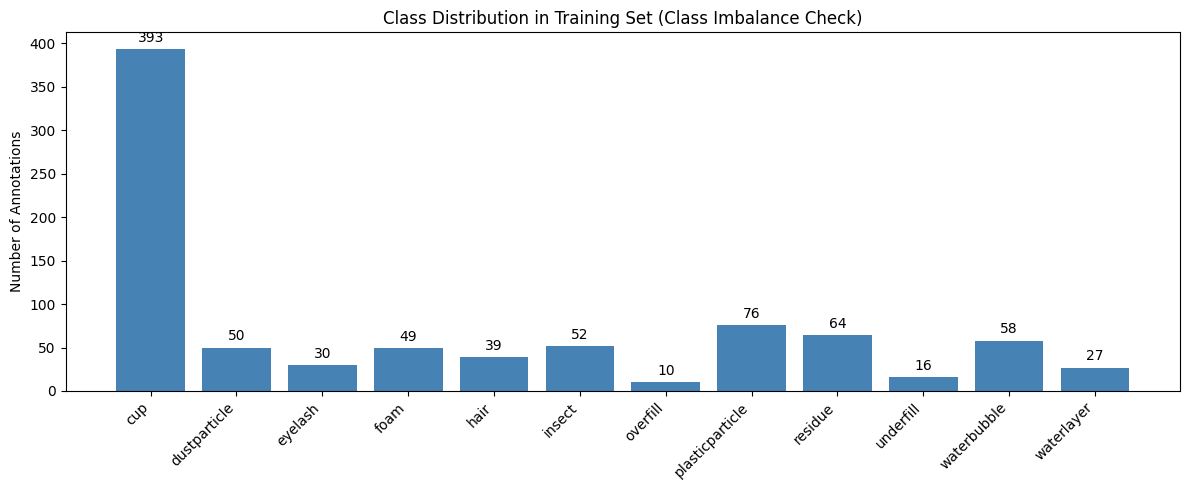

In [40]:
class_names = data_config["names"]
counts = Counter()

for lbl_file in glob.glob(f"{base_dir}/train_balanced/**/labels/*.txt", recursive=True):
    with open(lbl_file, "r") as f:
        for line in f:
            vals = line.strip().split()
            if vals:
                counts[int(vals.pop(0))] += 1

labels = [class_names[i] for i in range(len(class_names))]
values = [counts[i] for i in range(len(class_names))]

plt.figure(figsize=(12, 5))
bars = plt.bar(labels, values, color="steelblue")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Number of Annotations")
plt.title("Class Distribution in Training Set (Class Imbalance Check)")
plt.bar_label(bars, padding=3)
plt.tight_layout()
plt.show()

In [18]:
sample_img_path = glob.glob(f"{base_dir}/train_balanced/**/images/*.*", recursive=True).pop(0)
orig_img = cv2.cvtColor(cv2.imread(sample_img_path), cv2.COLOR_BGR2RGB)

# Resize to 640x640 and normalize pixel intensities to [0, 1]
resized_img = cv2.resize(orig_img, (640, 640))
normalized_img = resized_img.astype(np.float32) / 255.0

print("Original shape & dtype  :", orig_img.shape, orig_img.dtype)
print("Resized shape           :", resized_img.shape)
print("Normalized dtype & range:", normalized_img.dtype, f"[{normalized_img.min():.2f}, {normalized_img.max():.2f}]")

Original shape & dtype  : (640, 640, 3) uint8
Resized shape           : (640, 640, 3)
Normalized dtype & range: float32 [0.00, 1.00]


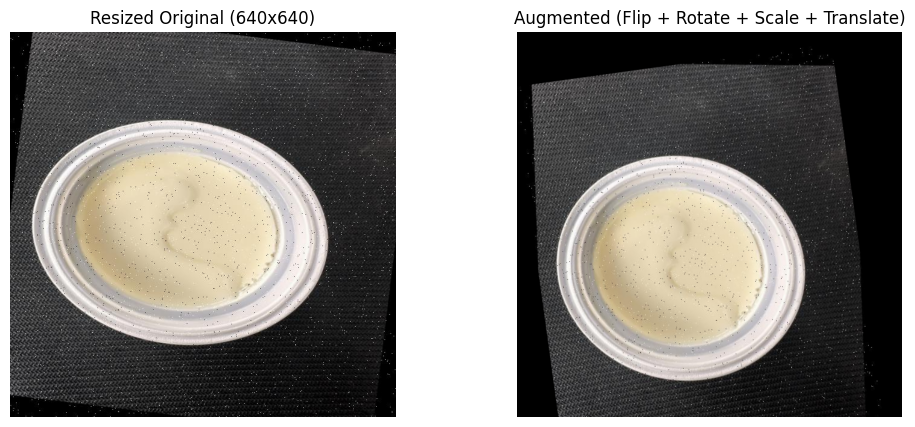

In [19]:
!pip install -q albumentations
import albumentations as A

transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.Affine(
        scale=(0.8, 1.2),
        translate_percent=(-0.1, 0.1),
        rotate=(-20, 20),
        p=0.8
    )
], bbox_params=A.BboxParams(format="yolo", label_fields=["class_labels"], clip=True))

base_name, _ = os.path.splitext(sample_img_path)
lbl_path = base_name.replace("/images/", "/labels/") + ".txt"

bboxes, cls_labels = [], []
with open(lbl_path, "r") as f:
    for line in f:
        vals = list(map(float, line.strip().split()))
        if not vals:
            continue
        cid = int(vals.pop(0))
        if len(vals) == 4:
            bboxes.append(vals)
        else:
            xs, ys = vals[0::2], vals[1::2]
            xc, yc = (min(xs) + max(xs)) / 2, (min(ys) + max(ys)) / 2
            bw, bh = max(xs) - min(xs), max(ys) - min(ys)
            bboxes.append([xc, yc, bw, bh])
        cls_labels.append(cid)

augmented = transform(image=resized_img, bboxes=bboxes, class_labels=cls_labels)
aug_img = augmented["image"]

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(resized_img)
ax[0].set_title("Resized Original (640x640)")
ax[0].axis("off")

ax[1].imshow(aug_img)
ax[1].set_title("Augmented (Flip + Rotate + Scale + Translate)")
ax[1].axis("off")
plt.show()

In [20]:
import yaml

data_config["path"] = base_dir
data_config["train"] = "train_balanced/train_balanced/images"
data_config["val"] = "val_balanced/val_balanced/images"
data_config["test"] = "test/test/images"

with open(yaml_path, "w") as f:
    yaml.safe_dump(data_config, f)

print("Dataset prepared and verified at:", yaml_path)
print("Ready for YOLOv11 training!")

Dataset prepared and verified at: /root/.cache/kagglehub/datasets/chavidubandara/dairyfusion-ai-yoghurt-cup-defect-dataset/versions/1/data_balanced.yaml
Ready for YOLOv11 training!


In [21]:
import pandas as pd

class_names = data_config["names"]
records = []

for split in ["train_balanced", "val_balanced", "test"]:
    for lbl_file in glob.glob(f"{base_dir}/{split}/**/labels/*.txt", recursive=True):
        with open(lbl_file, "r") as f:
            for line in f:
                vals = list(map(float, line.strip().split()))
                if not vals:
                    continue
                cls_id = int(vals.pop(0))
                if len(vals) == 4:
                    xc, yc, bw, bh = vals
                else:
                    xs, ys = vals[0::2], vals[1::2]
                    xc, yc = (min(xs) + max(xs)) / 2, (min(ys) + max(ys)) / 2
                    bw, bh = max(xs) - min(xs), max(ys) - min(ys)

                records.append({
                    "split": split,
                    "class_id": cls_id,
                    "class_name": class_names[cls_id],
                    "x_center": xc,
                    "y_center": yc,
                    "width": bw,
                    "height": bh,
                    "area": bw * bh,
                    "aspect_ratio": bw / bh if bh > 0 else 0
                })

df = pd.DataFrame(records)

print("=== Bounding Box Statistical Summary ===")
display(df[["x_center", "y_center", "width", "height", "area", "aspect_ratio"]].describe().round(4))

print("\n=== Class Distribution Across Splits ===")
split_summary = pd.crosstab(df["class_name"], df["split"], margins=True, margins_name="Total")
display(split_summary)

defects_df = df[df["class_name"].str.lower() != "cup"]
defect_counts = defects_df["class_name"].value_counts()
print("\n=== Top Occurring Defect Categories ===")
print(defect_counts)

max_cls, min_cls = defect_counts.max(), defect_counts.min()
print(f"\nDefect Imbalance Ratio (Max / Min): {max_cls} / {min_cls} = {max_cls / min_cls:.2f}x")

=== Bounding Box Statistical Summary ===


,x_center,y_center,width,height,area,aspect_ratio
count,1073.0000,1073.0000,1073.0000,1073.0000,1073.0000,1073.0000
mean,0.4961,0.5220,0.5369,0.4174,0.3294,1.2829
std,0.0821,0.0655,0.3745,0.2879,0.3054,0.3069
min,0.1766,0.2977,0.0414,0.0336,0.0017,0.5123
25%,0.4695,0.4940,0.1391,0.1102,0.0146,1.2270
50%,0.4980,0.5215,0.5864,0.4352,0.2545,1.3152
75%,0.5241,0.5544,0.9309,0.7056,0.6545,1.3402
max,0.7711,0.7031,1.0000,0.9805,0.8585,4.5393



=== Class Distribution Across Splits ===


split,test,train_balanced,val_balanced,Total
class_name,,,,
cup,27,393,69,489
dustparticle,4,50,4,58
eyelash,2,30,4,36
foam,2,49,16,67
hair,5,39,5,49
insect,3,52,12,67
overfill,1,10,9,20
plasticparticle,4,76,8,88
residue,0,64,16,80



=== Top Occurring Defect Categories ===
class_name
plasticparticle    88
residue            80
insect             67
foam               67
waterbubble        62
dustparticle       58
hair               49
waterlayer         36
eyelash            36
underfill          21
overfill           20
Name: count, dtype: int64

Defect Imbalance Ratio (Max / Min): 88 / 20 = 4.40x


/tmp/ipykernel_496/388928386.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=all_counts.index, y=all_counts.values, ax=axes[0], palette="viridis")
/tmp/ipykernel_496/388928386.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=defect_counts.values, y=defect_counts.index, ax=axes[1], palette="magma")


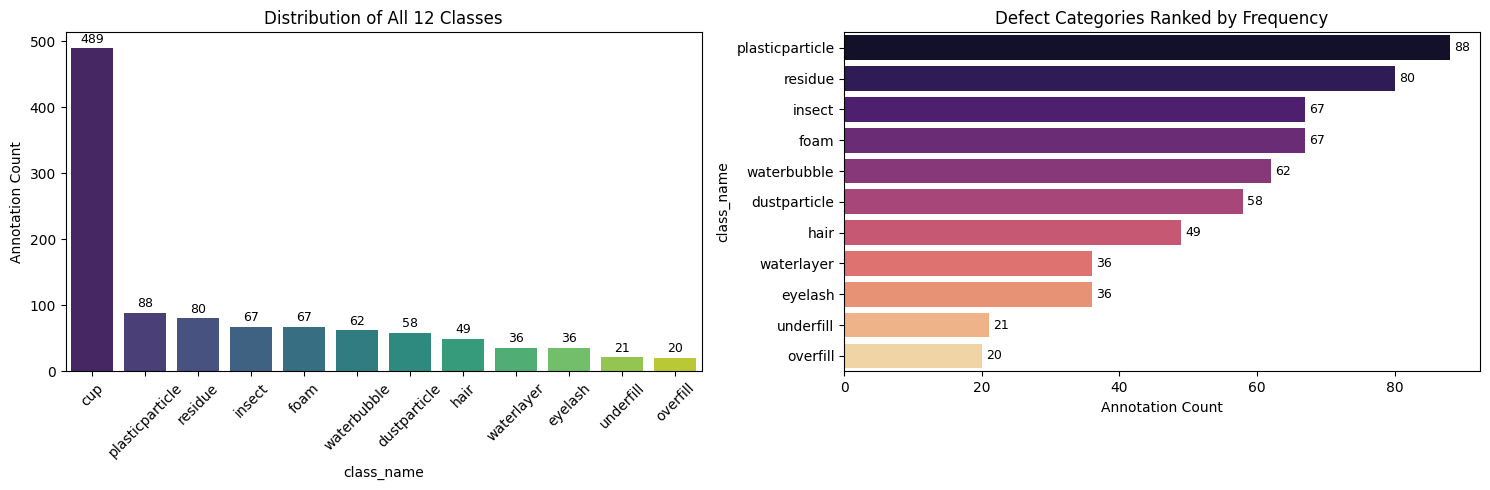

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

all_counts = df["class_name"].value_counts()
sns.barplot(x=all_counts.index, y=all_counts.values, ax=axes[0], palette="viridis")
axes[0].set_title("Distribution of All 12 Classes")
axes[0].set_ylabel("Annotation Count")
axes[0].tick_params(axis="x", rotation=45)
for container in axes[0].containers:
    axes[0].bar_label(container, padding=2, fontsize=9)

sns.barplot(x=defect_counts.values, y=defect_counts.index, ax=axes[1], palette="magma")
axes[1].set_title("Defect Categories Ranked by Frequency")
axes[1].set_xlabel("Annotation Count")
for container in axes[1].containers:
    axes[1].bar_label(container, padding=3, fontsize=9)

plt.tight_layout()
plt.show()

/tmp/ipykernel_496/2531402943.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="class_name", y="area", ax=axes[1], palette="Set2")


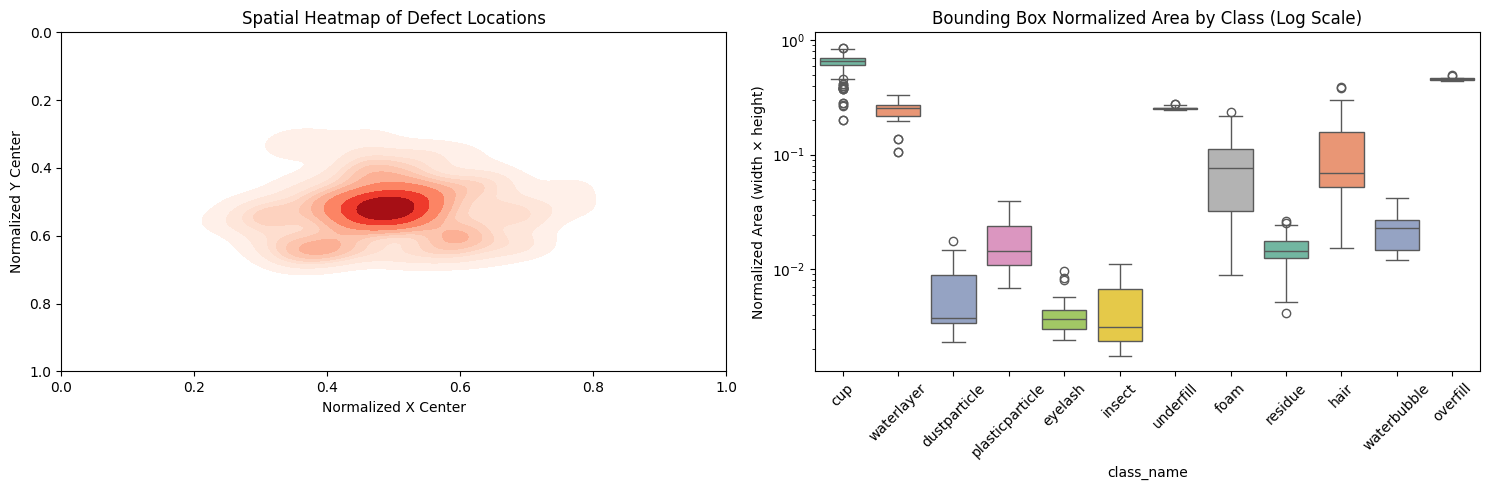

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.kdeplot(
    data=defects_df, x="x_center", y="y_center",
    fill=True, cmap="Reds", thresh=0.05, ax=axes[0]
)
axes[0].set_xlim(0, 1)
axes[0].set_ylim(1, 0)
axes[0].set_title("Spatial Heatmap of Defect Locations")
axes[0].set_xlabel("Normalized X Center")
axes[0].set_ylabel("Normalized Y Center")

sns.boxplot(data=df, x="class_name", y="area", ax=axes[1], palette="Set2")
axes[1].set_yscale("log")
axes[1].set_title("Bounding Box Normalized Area by Class (Log Scale)")
axes[1].set_ylabel("Normalized Area (width × height)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

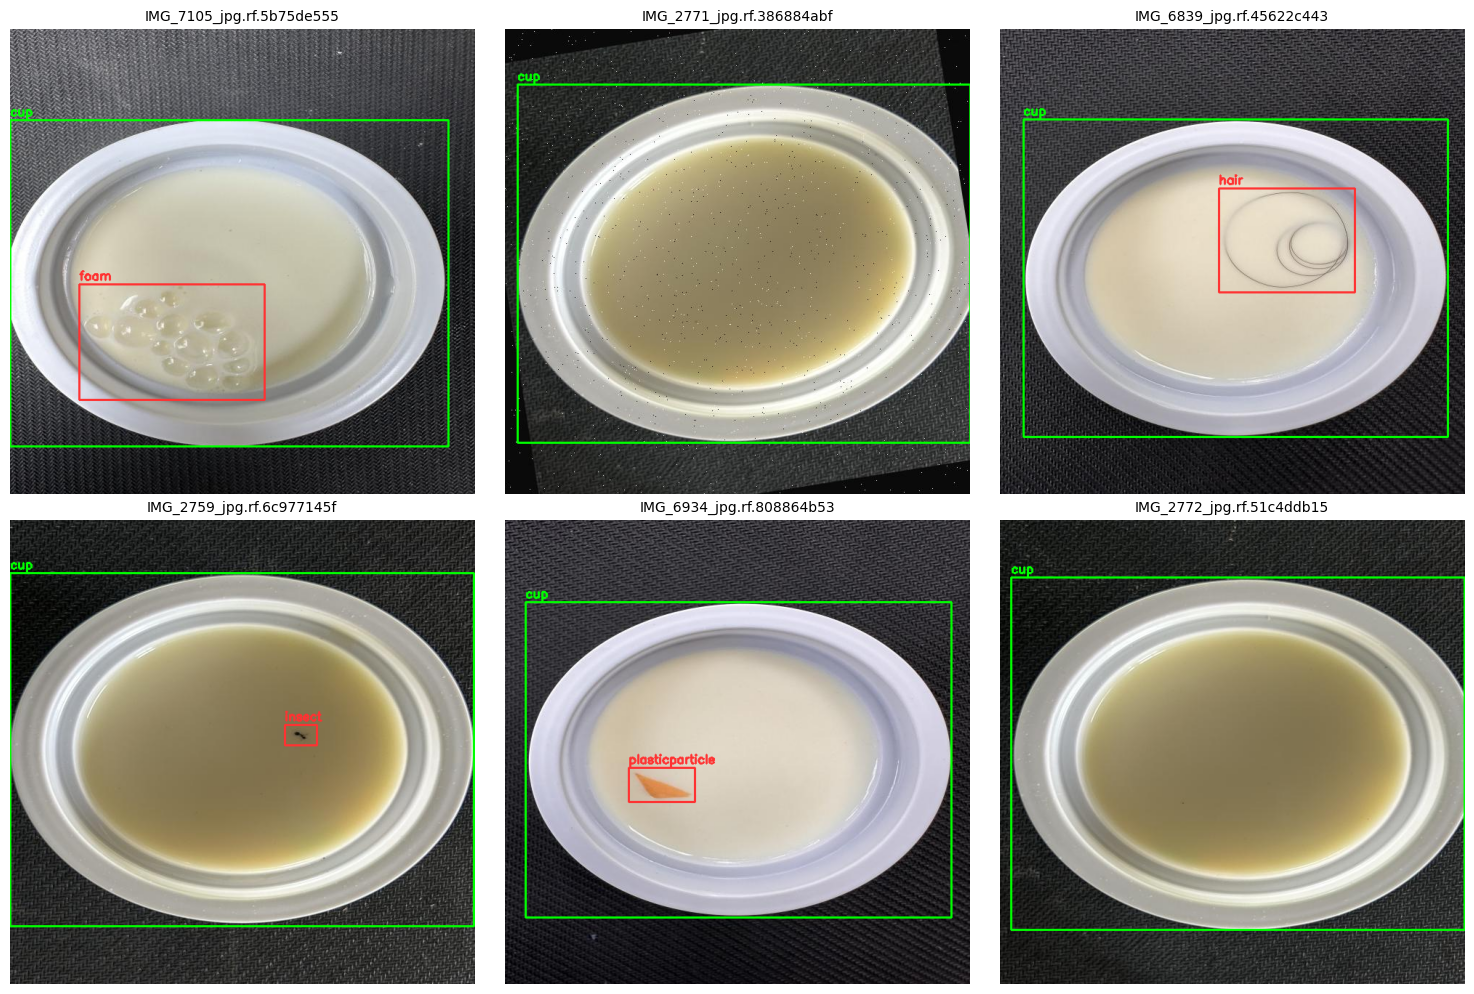

In [24]:
import cv2
import random

sample_paths = glob.glob(f"{base_dir}/train_balanced/**/images/*.*", recursive=True)
chosen_imgs = random.sample(sample_paths, min(6, len(sample_paths)))

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for idx, img_path in enumerate(chosen_imgs):
    img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    h, w, _ = img.shape

    base_name, _ = os.path.splitext(img_path)
    lbl_path = base_name.replace("/images/", "/labels/") + ".txt"

    if os.path.exists(lbl_path):
        with open(lbl_path, "r") as f:
            for line in f:
                vals = list(map(float, line.strip().split()))
                if not vals:
                    continue
                cid = int(vals.pop(0))
                if len(vals) == 4:
                    xc, yc, bw, bh = vals
                    x1, y1 = int((xc - bw / 2) * w), int((yc - bh / 2) * h)
                    x2, y2 = int((xc + bw / 2) * w), int((yc + bh / 2) * h)
                else:
                    xs, ys = vals[0::2], vals[1::2]
                    x1, y1 = int(min(xs) * w), int(min(ys) * h)
                    x2, y2 = int(max(xs) * w), int(max(ys) * h)

                color = (0, 255, 0) if class_names[cid].lower() == "cup" else (255, 50, 50)
                cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
                cv2.putText(img, class_names[cid], (x1, max(y1 - 6, 15)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.55, color, 2)

    axes[idx].imshow(img)
    axes[idx].set_title(os.path.basename(img_path)[:25], fontsize=10)
    axes[idx].axis("off")

plt.tight_layout()
plt.show()

In [25]:
!pip install -q ultralytics
from ultralytics import YOLO
import yaml

data_config["path"] = base_dir
data_config["train"] = "train_balanced/train_balanced/images"
data_config["val"] = "val_balanced/val_balanced/images"
data_config["test"] = "test/test/images"

with open(yaml_path, "w") as f:
    yaml.safe_dump(data_config, f)

model = YOLO("yolo11s.pt")

results = model.train(
    data=yaml_path,
    epochs=60,
    imgsz=640,
    batch=16,
    patience=15,
    project="dairyfusion_yolo11",
    name="defect_detector"
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/root/.cache/kagglehub/datasets/chavidubandara/dairyfusion-ai-yoghurt-cup-defect-dataset/versions/1/data_balanced.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60,

In [27]:
import glob
from ultralytics import YOLO

weights_files = glob.glob("/content/**/weights/best.pt", recursive=True)
print("Found best.pt files:", weights_files)

if not weights_files:
    print("No best.pt found! Please run the model.train() cell first and wait for it to finish.")
else:
    best_weights_path = weights_files[-1]
    print("Loading:", best_weights_path)
    best_model = YOLO(best_weights_path)

Found best.pt files: ['/content/runs/detect/dairyfusion_yolo11/defect_detector/weights/best.pt']
Loading: /content/runs/detect/dairyfusion_yolo11/defect_detector/weights/best.pt


In [28]:
import numpy as np
import pandas as pd

metrics = best_model.val(data=yaml_path, split="test")

precision = metrics.box.mp
recall = metrics.box.mr
f1_score = 2 * (precision * recall) / (precision + recall + 1e-16)
map50 = metrics.box.map50
map50_95 = metrics.box.map

print("=== Overall Test Set Performance ===")
print(f"Precision : {precision:.4f} ({precision*100:.2f}%)")
print(f"Recall    : {recall:.4f} ({recall*100:.2f}%)")
print(f"F1-Score  : {f1_score:.4f} ({f1_score*100:.2f}%)")
print(f"mAP@50    : {map50:.4f} ({map50*100:.2f}%)")
print(f"mAP@50-95 : {map50_95:.4f} ({map50_95*100:.2f}%)")

class_rows = []
for i, cls_idx in enumerate(metrics.ap_class_index):
    p_c = metrics.box.p[i]
    r_c = metrics.box.r[i]
    f1_c = 2 * (p_c * r_c) / (p_c + r_c + 1e-16)
    ap50_c = metrics.box.ap50[i]
    class_rows.append({
        "Class": best_model.names[cls_idx],
        "Precision": round(p_c, 4),
        "Recall": round(r_c, 4),
        "F1-Score": round(f1_c, 4),
        "mAP@50": round(ap50_c, 4)
    })

print("\n=== Per-Class Evaluation Metrics ===")
display(pd.DataFrame(class_rows))

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,417,444 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 132.8±230.8 MB/s, size: 54.4 KB)
val: Scanning /root/.cache/kagglehub/datasets/chavidubandara/dairyfusion-ai-yoghurt-cup-defect-dataset/versions/1/test/test/labels... 27 images, 0 backgrounds, 21 corrupt: 100% ━━━━━━━━━━━━ 27/27 1.3Kit/s 0.0s
val: /root/.cache/kagglehub/datasets/chavidubandara/dairyfusion-ai-yoghurt-cup-defect-dataset/versions/1/test/test/images/IMG_2812_jpg.rf.b5f9ef1ef52a8300418e62178b0d6cc9.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /root/.cache/kagglehub/datasets/chavidubandara/dairyfusion-ai-yoghurt-cup-defect-dataset/versions/1/test/test/images/IMG_2848_jpg.rf.62c104d7ebacd29699b0b99ce2434121.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /root/.cache/kagglehub/datasets/chavidubandara

,Class,Precision,Recall,F1-Score,mAP@50
0,cup,0.9902,1.0,0.9951,0.995
1,overfill,0.9626,1.0,0.9810,0.995
2,waterlayer,0.9889,1.0,0.9944,0.995


In [29]:
import glob
import os

test_images_dir = os.path.join(base_dir, "test", "test", "images")

pred_results = best_model.predict(
    source=test_images_dir,
    conf=0.25,
    save=True,
    project="dairyfusion_yolo11",
    name="test_predictions"
)

for res in pred_results[:5]:
    img_name = os.path.basename(res.path)
    print(f"\nImage: {img_name} -> {len(res.boxes)} object(s) detected:")
    for box in res.boxes:
        cls_id = int(box.cls[0])
        conf = float(box.conf[0])
        coords = [round(x, 1) for x in box.xyxy[0].tolist()]
        print(f"  - {best_model.names[cls_id]:<15} | Confidence: {conf*100:.2f}% | Box (xyxy): {coords}")


image 1/27 /root/.cache/kagglehub/datasets/chavidubandara/dairyfusion-ai-yoghurt-cup-defect-dataset/versions/1/test/test/images/IMG_2812_jpg.rf.b5f9ef1ef52a8300418e62178b0d6cc9.jpg: 640x640 1 cup, 15.9ms
image 2/27 /root/.cache/kagglehub/datasets/chavidubandara/dairyfusion-ai-yoghurt-cup-defect-dataset/versions/1/test/test/images/IMG_2848_jpg.rf.62c104d7ebacd29699b0b99ce2434121.jpg: 640x640 1 cup, 1 waterlayer, 16.5ms
image 3/27 /root/.cache/kagglehub/datasets/chavidubandara/dairyfusion-ai-yoghurt-cup-defect-dataset/versions/1/test/test/images/IMG_2851_jpg.rf.233018fab17a3ea812debb9e648ddac9.jpg: 640x640 1 cup, 1 waterlayer, 15.9ms
image 4/27 /root/.cache/kagglehub/datasets/chavidubandara/dairyfusion-ai-yoghurt-cup-defect-dataset/versions/1/test/test/images/IMG_2872_jpg.rf.1384f21a581d56d966ef3be8c2089b66.jpg: 640x640 1 cup, 16.2ms
image 5/27 /root/.cache/kagglehub/datasets/chavidubandara/dairyfusion-ai-yoghurt-cup-defect-dataset/versions/1/test/test/images/IMG_2874_jpg.rf.defd4936b88

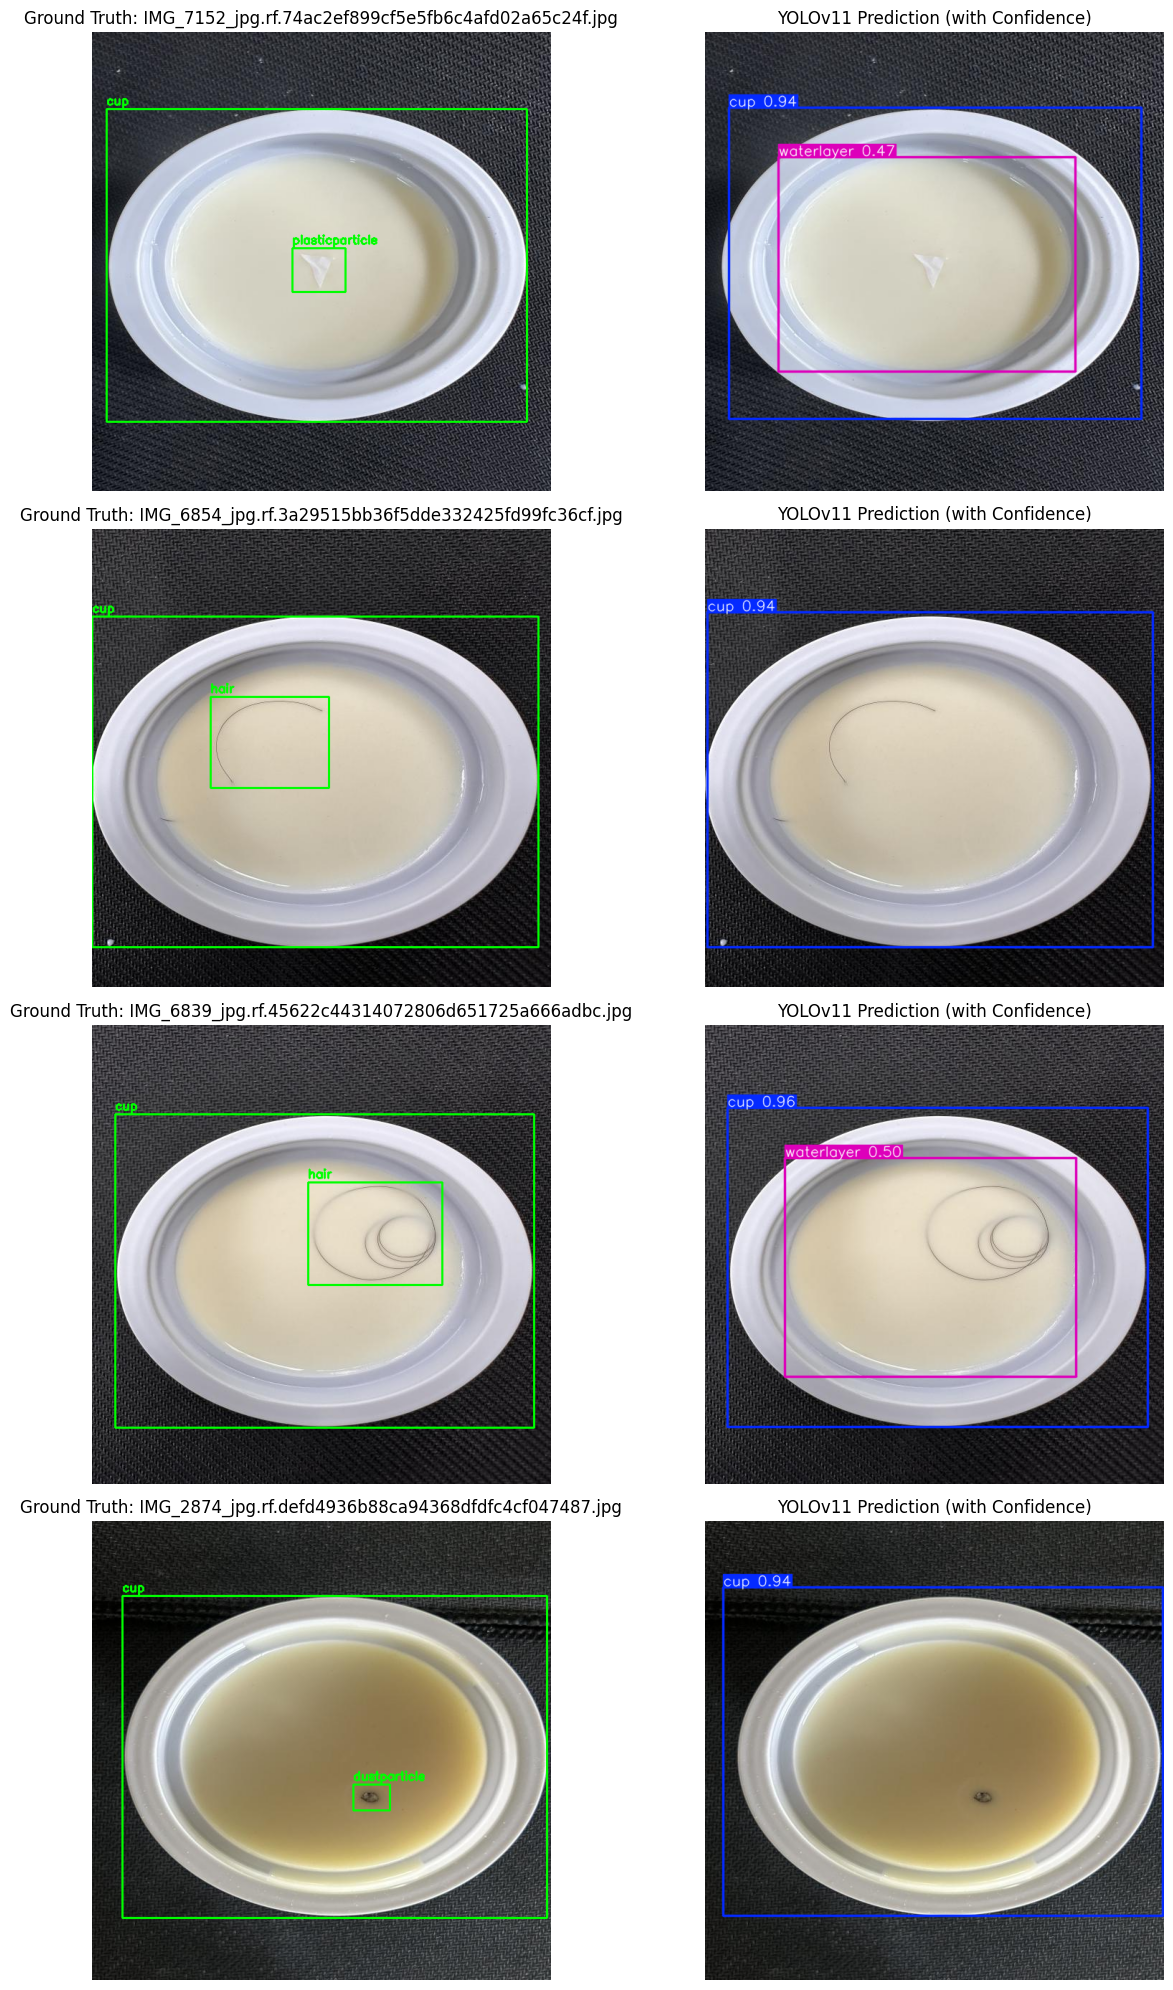

In [30]:
import cv2
import matplotlib.pyplot as plt
import random

test_imgs = glob.glob(f"{test_images_dir}/*.*")
sample_test_imgs = random.sample(test_imgs, min(4, len(test_imgs)))
class_names = data_config["names"]

fig, axes = plt.subplots(len(sample_test_imgs), 2, figsize=(14, 5 * len(sample_test_imgs)))
if len(sample_test_imgs) == 1:
    axes = [axes]

for row_idx, img_path in enumerate(sample_test_imgs):
    gt_img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    h, w, _ = gt_img.shape
    base_name, _ = os.path.splitext(img_path)
    lbl_path = base_name.replace("/images/", "/labels/") + ".txt"

    if os.path.exists(lbl_path):
        with open(lbl_path, "r") as f:
            for line in f:
                vals = list(map(float, line.strip().split()))
                if not vals:
                    continue
                cid = int(vals.pop(0))
                if len(vals) == 4:
                    xc, yc, bw, bh = vals
                    x1, y1 = int((xc - bw / 2) * w), int((yc - bh / 2) * h)
                    x2, y2 = int((xc + bw / 2) * w), int((yc + bh / 2) * h)
                else:
                    xs, ys = vals[0::2], vals[1::2]
                    x1, y1 = int(min(xs) * w), int(min(ys) * h)
                    x2, y2 = int(max(xs) * w), int(max(ys) * h)

                cv2.rectangle(gt_img, (x1, y1), (x2, y2), (0, 255, 0), 2)
                cv2.putText(gt_img, class_names[cid], (x1, max(y1 - 6, 15)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 255, 0), 2)


    res = best_model.predict(source=img_path, conf=0.25, verbose=False)[0]
    pred_img = cv2.cvtColor(res.plot(), cv2.COLOR_BGR2RGB)

    axes[row_idx][0].imshow(gt_img)
    axes[row_idx][0].set_title(f"Ground Truth: {os.path.basename(img_path)}")
    axes[row_idx][0].axis("off")

    axes[row_idx][1].imshow(pred_img)
    axes[row_idx][1].set_title("YOLOv11 Prediction (with Confidence)")
    axes[row_idx][1].axis("off")

plt.tight_layout()
plt.show()

In [31]:
!pip install -q sentence-transformers faiss-cpu transformers accelerate

In [32]:
import faiss
import numpy as np
from sentence_transformers import SentenceTransformer

kb_definitions = {
    "cup": {
        "category": "Container / Baseline Object",
        "description": "Standard yoghurt cup container detected in the inspection frame.",
        "action": "Proceed with defect inspection across the cup surface, rim, and fill level."
    },
    "dustparticle": {
        "category": "Surface / Foreign Particle Contamination",
        "description": "Tiny airborne dust particles settled on the yoghurt surface or inner cup rim.",
        "action": "Reject batch unit; inspect cleanroom HEPA filtration and filling-line air pressure."
    },
    "eyelash": {
        "category": "Biological / Hygiene Contamination",
        "description": "Human eyelash filament present on or inside the yoghurt product.",
        "action": "Immediate quarantine and rejection; enforce operator PPE, hairnet, and face-shield compliance."
    },
    "foam": {
        "category": "Process / Aeration Anomaly",
        "description": "Excessive air bubbles or frothy foam layer on top of the yoghurt.",
        "action": "Flag for quality review; check filling nozzle pressure, pump cavitation, and product temperature."
    },
    "hair": {
        "category": "Biological / Hygiene Contamination",
        "description": "Human hair strand detected on the yoghurt surface or cup edge.",
        "action": "Immediate rejection; audit gowning procedures and hygiene barriers along the packaging line."
    },
    "insect": {
        "category": "Critical Bio-Hazard Contamination",
        "description": "Whole or partial insect contamination inside the yoghurt cup.",
        "action": "Critical line halt and batch recall; trigger pest-control sanitation and air-curtain inspection."
    },
    "overfill": {
        "category": "Dosing / Volume Defect",
        "description": "Yoghurt fill level exceeds maximum threshold, risking lid seal contamination and spillage.",
        "action": "Divert cup; recalibrate volumetric piston filler and dosing valve timing."
    },
    "underfill": {
        "category": "Dosing / Volume Defect",
        "description": "Yoghurt volume falls below minimum net-weight specification.",
        "action": "Reject unit; inspect hopper feed pressure and nozzle clogging."
    },
    "scratch": {
        "category": "Packaging Structural Defect",
        "description": "Visible abrasion or scratch mark on the cup wall or rim that may weaken barrier integrity.",
        "action": "Inspect cup denester and conveyor guide rails for sharp friction points."
    },
    "dent": {
        "category": "Packaging Structural Defect",
        "description": "Physical deformation or dent in the yoghurt cup body, risking poor heat-sealing.",
        "action": "Remove deformed cup; check mechanical handling grippers and stack pressure."
    },
    "stain": {
        "category": "Cosmetic / Surface Residue Defect",
        "description": "Product splash, residue, or discoloration on the outer cup wall or sealing rim.",
        "action": "Clean sealing jaws; adjust nozzle anti-drip suck-back settings."
    },
    "crack": {
        "category": "Critical Packaging Integrity Defect",
        "description": "Fracture or split in the plastic cup wall causing leakage and spoilage risk.",
        "action": "Immediate rejection; inspect thermoformed cup batch quality and conveyor impact points."
    }
}

kb_documents = []
for cls_id, cls_name in best_model.names.items():
    key = cls_name.lower().replace(" ", "").replace("_", "")
    info = kb_definitions.get(key, {
        "category": "Quality Defect",
        "description": f"Detected anomaly classified as '{cls_name}' on the yoghurt cup.",
        "action": "Flag unit for manual quality assurance inspection."
    })
    doc_text = (
        f"Class: {cls_name} | Category: {info['category']} | "
        f"Description: {info['description']} | Recommended Action: {info['action']}"
    )
    kb_documents.append(doc_text)

embedder = SentenceTransformer("all-MiniLM-L6-v2")
embeddings = embedder.encode(kb_documents, convert_to_numpy=True)
faiss.normalize_L2(embeddings)

dimension = embeddings.shape[1]
faiss_index = faiss.IndexFlatIP(dimension)
faiss_index.add(embeddings)

print(f"Indexed {faiss_index.ntotal} structured class documents in FAISS (dim={dimension}).")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Indexed 12 structured class documents in FAISS (dim=384).


In [33]:
import glob
import os
import torch
from transformers import pipeline

llm = pipeline(
    "text-generation",
    model="Qwen/Qwen2.5-1.5B-Instruct",
    torch_dtype=torch.float16,
    device_map="auto"
)

def generate_rag_defect_summary(image_path, conf_thresh=0.25, top_k=3):
    results = best_model.predict(source=image_path, conf=conf_thresh, verbose=False)[0]

    detections = []
    for box in results.boxes:
        cls_name = best_model.names[int(box.cls)]
        conf = float(box.conf)
        coords = [round(x, 1) for x in box.xyxy[0].tolist()]
        detections.append({"class": cls_name, "confidence": conf, "bbox": coords})

    if not detections:
        return "No yoghurt cup or defects detected in the image.", []


    defect_only = [d for d in detections if d["class"].lower() != "cup"]
    target_items = defect_only if defect_only else detections

    unique_classes = list(dict.fromkeys(d["class"] for d in target_items))
    query_text = "Yoghurt cup quality inspection detected: " + ", ".join(unique_classes)


    query_vec = embedder.encode([query_text], convert_to_numpy=True)
    faiss.normalize_L2(query_vec)
    scores, indices = faiss_index.search(query_vec, min(top_k, len(kb_documents)))

    retrieved_context = [kb_documents[idx] for idx in indices[0] if idx != -1]


    detection_summary = "\n".join(
        [f"- {d['class']} (Confidence: {d['confidence']*100:.1f}%, Box: {d['bbox']})" for d in detections]
    )
    context_block = "\n".join([f"- {doc}" for doc in retrieved_context])

    messages = [
        {
            "role": "system",
            "content": "You are a Dairy Quality Assurance AI Assistant. Summarize detected yoghurt cup defects clearly, explain their severity using the retrieved knowledge base, and state whether the cup passes or fails inspection."
        },
        {
            "role": "user",
            "content": (
                f"Image File: {os.path.basename(image_path)}\n\n"
                f"YOLOv11 Detections:\n{detection_summary}\n\n"
                f"Retrieved Knowledge Base Context:\n{context_block}\n\n"
                f"Generate a concise, natural-language inspection summary and recommended action."
            )
        }
    ]


    output = llm(messages, max_new_tokens=220, temperature=0.3, do_sample=True)
    summary_text = output[0]["generated_text"][-1]["content"]
    return summary_text, retrieved_context

test_imgs = glob.glob(f"{base_dir}/test/**/images/*.*", recursive=True)
sample_test_img = test_imgs[0]

summary, context_used = generate_rag_defect_summary(sample_test_img)

print("=== Image Inspected ===")
print(os.path.basename(sample_test_img))
print("\n=== Retrieved FAISS Context ===")
for c in context_used:
    print(" •", c)
print("\n=== LLM Natural-Language Defect Summary ===")
print(summary)

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

=== Image Inspected ===
IMG_3083_jpg.rf.ba6a571cfbaa57f64ee8ba6a8134e80a.jpg

=== Retrieved FAISS Context ===
 • Class: cup | Category: Container / Baseline Object | Description: Standard yoghurt cup container detected in the inspection frame. | Recommended Action: Proceed with defect inspection across the cup surface, rim, and fill level.
 • Class: overfill | Category: Dosing / Volume Defect | Description: Yoghurt fill level exceeds maximum threshold, risking lid seal contamination and spillage. | Recommended Action: Divert cup; recalibrate volumetric piston filler and dosing valve timing.
 • Class: residue | Category: Quality Defect | Description: Detected anomaly classified as 'residue' on the yoghurt cup. | Recommended Action: Flag unit for manual quality assurance inspection.

=== LLM Natural-Language Defect Summary ===
**Inspection Summary:**
The detected image shows a standard yoghurt cup container with an overfilled condition. The cup is located at coordinates (18.5, 111.8) to 

In [34]:
!pip install streamlit plotly pyngrok --quiet

In [35]:
part1 = '''import os
import glob
from datetime import datetime
import cv2
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import streamlit as st
from PIL import Image
from ultralytics import YOLO
import faiss
import torch
from sentence_transformers import SentenceTransformer
from transformers import pipeline

st.set_page_config(page_title="DairyFusion AI - Yoghurt Cup Defect Inspection", layout="wide")

@st.cache_resource
def load_yolo_model():
    weights = glob.glob("/content/**/weights/best.pt", recursive=True)
    if not weights:
        st.error("Trained weights (best.pt) not found! Please run Task 4 training first.")
        st.stop()
    return YOLO(weights[-1])

@st.cache_resource
def load_rag_pipeline(_class_names):
    kb_definitions = {
        "cup": ("Container", "Standard yoghurt cup container detected.", "Proceed with defect inspection."),
        "dustparticle": ("Surface Contamination", "Airborne dust particles on yoghurt surface or rim.", "Reject unit; check HEPA air filtration."),
        "eyelash": ("Biological Contamination", "Human eyelash filament inside or on the cup.", "Immediate quarantine; enforce operator PPE."),
        "foam": ("Process Anomaly", "Excessive air bubbles or froth on yoghurt top.", "Check filling nozzle pressure and temperature."),
        "hair": ("Biological Contamination", "Human hair strand detected on yoghurt or rim.", "Immediate rejection; audit line hygiene barriers."),
        "insect": ("Critical Bio-Hazard", "Insect contamination inside the yoghurt cup.", "Critical line halt and batch sanitation."),
        "overfill": ("Dosing Defect", "Fill level exceeds maximum threshold.", "Divert cup; recalibrate piston filler."),
        "underfill": ("Dosing Defect", "Yoghurt volume below minimum specification.", "Reject unit; check hopper feed and nozzle."),
        "scratch": ("Packaging Defect", "Abrasion or scratch on cup wall or rim.", "Inspect denester and conveyor guide rails."),
        "dent": ("Packaging Defect", "Physical deformation in cup body risking seal failure.", "Remove deformed cup; check mechanical grippers."),
        "stain": ("Cosmetic Residue", "Product splash or residue on outer wall or rim.", "Clean sealing jaws; adjust anti-drip nozzle."),
        "crack": ("Critical Integrity Defect", "Fracture or split in plastic cup causing leakage.", "Immediate rejection; inspect cup batch quality.")
    }
    kb_docs = []
    for _, name in _class_names.items():
        key = name.lower().replace(" ", "").replace("_", "")
        cat, desc, act = kb_definitions.get(key, ("Quality Defect", f"Detected anomaly: {name}.", "Flag for QA inspection."))
        kb_docs.append(f"Class: {name} | Category: {cat} | Description: {desc} | Action: {act}")

    embedder = SentenceTransformer("all-MiniLM-L6-v2")
    embeddings = embedder.encode(kb_docs, convert_to_numpy=True)
    faiss.normalize_L2(embeddings)
    index = faiss.IndexFlatIP(embeddings.shape[1])
    index.add(embeddings)

    llm = pipeline(
        "text-generation",
        model="Qwen/Qwen2.5-1.5B-Instruct",
        torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
        device_map="auto"
    )
    return embedder, index, kb_docs, llm

yolo_model = load_yolo_model()
embedder, faiss_index, kb_docs, llm = load_rag_pipeline(yolo_model.names)
'''

with open("app.py", "w") as f:
    f.write(part1)
print("Part 1 saved!")

Part 1 saved!


In [36]:
part2 = '''
st.sidebar.header("Inspection Settings")
conf_threshold = st.sidebar.slider("Confidence Threshold", 0.10, 0.95, 0.25, 0.05)

st.title("DairyFusion AI: Yoghurt Cup Defect Detection & RAG Quality Assistant")
tab1, tab2 = st.tabs(["Image Defect Inspection", "Model Performance & Dataset Analytics"])

with tab1:
    uploaded_file = st.file_uploader("Upload a Yoghurt Cup Image (JPG, PNG)", type=["jpg", "jpeg", "png"])
    if uploaded_file is not None:
        pil_img = Image.open(uploaded_file).convert("RGB")
        img_np = np.array(pil_img)
        results = yolo_model.predict(source=img_np, conf=conf_threshold, verbose=False)
        res = results[0]
        annotated_rgb = cv2.cvtColor(res.plot(), cv2.COLOR_BGR2RGB)

        col1, col2 = st.columns(2)
        col1.subheader("Uploaded Image")
        col1.image(pil_img, use_container_width=True)
        col2.subheader("YOLOv11 Predicted Bounding Boxes")
        col2.image(annotated_rgb, use_container_width=True)

        detections = []
        for box in res.boxes:
            cls_name = yolo_model.names[int(box.cls)]
            conf = float(box.conf)
            x1, y1, x2, y2 = [round(v, 1) for v in box.xyxy.tolist()[0]]
            detections.append({
                "Detected Class": cls_name,
                "Confidence (%)": round(conf * 100, 2),
                "BBox (x1, y1, x2, y2)": f"[{x1}, {y1}, {x2}, {y2}]"
            })

        st.divider()
        c_left, c_right = st.columns(2)
        with c_left:
            st.subheader("Detected Classes & Confidence Scores")
            if detections:
                det_df = pd.DataFrame(detections)
                st.dataframe(det_df, use_container_width=True, hide_index=True)
                counts_df = det_df["Detected Class"].value_counts().reset_index()
                counts_df.columns = ["Class", "Count"]
                st.plotly_chart(px.bar(counts_df, x="Class", y="Count", color="Class", text_auto=True), use_container_width=True)
            else:
                st.info("No objects detected above threshold.")

        with c_right:
            st.subheader("RAG-Based Defect Inspection Summary")
            if detections:
                with st.spinner("Generating RAG inspection summary..."):
                    defects_only = [d for d in detections if d["Detected Class"].lower() != "cup"]
                    target_list = defects_only if defects_only else detections
                    unique_cls = list(dict.fromkeys(d["Detected Class"] for d in target_list))

                    query = "Yoghurt cup quality inspection detected: " + ", ".join(unique_cls)
                    q_vec = embedder.encode([query], convert_to_numpy=True)
                    faiss.normalize_L2(q_vec)
                    _, idxs = faiss_index.search(q_vec, min(3, len(kb_docs)))
                    retrieved = [kb_docs[i] for i in idxs[0] if i != -1]

                    det_lines = "\\n".join([f"- {d['Detected Class']} ({d['Confidence (%)']}%)" for d in detections])
                    ctx_lines = "\\n".join([f"- {r}" for r in retrieved])
                    messages = [
                        {"role": "system", "content": "You are a Dairy Quality Assurance AI Assistant. Give a pass/fail verdict, explain defects using context, and recommend actions."},
                        {"role": "user", "content": f"Detections:\\n{det_lines}\\n\\nContext:\\n{ctx_lines}\\n\\nSummarize inspection."}
                    ]
                    out = llm(messages, max_new_tokens=220, temperature=0.3, do_sample=True)
                    rag_summary = out[0]["generated_text"][-1]["content"]

                st.success(rag_summary)
                report_text = f"DAIRYFUSION AI REPORT\\nFile: {uploaded_file.name}\\n\\nDetections:\\n{det_lines}\\n\\nSummary:\\n{rag_summary}"
                st.download_button("Download Inspection Summary (.txt)", data=report_text, file_name="inspection_report.txt")

with tab2:
    st.subheader("YOLOv11 Model Performance & Training Analytics")
    results_csvs = glob.glob("/content/**/results.csv", recursive=True)
    if results_csvs:
        train_df = pd.read_csv(results_csvs[-1])
        train_df.columns = [c.strip() for c in train_df.columns]
        last_row = train_df.iloc[-1]
        c1, c2, c3, c4 = st.columns(4)
        c1.metric("Precision", f"{last_row.get('metrics/precision(B)', 0)*100:.2f}%")
        c2.metric("Recall", f"{last_row.get('metrics/recall(B)', 0)*100:.2f}%")
        c3.metric("mAP@50", f"{last_row.get('metrics/mAP50(B)', 0)*100:.2f}%")
        c4.metric("mAP@50-95", f"{last_row.get('metrics/mAP50-95(B)', 0)*100:.2f}%")

        fig_perf = go.Figure()
        for col, lbl in [("metrics/precision(B)", "Precision"), ("metrics/recall(B)", "Recall"), ("metrics/mAP50(B)", "mAP@50")]:
            if col in train_df.columns:
                fig_perf.add_trace(go.Scatter(x=train_df["epoch"], y=train_df[col], mode="lines+markers", name=lbl))
        st.plotly_chart(fig_perf, use_container_width=True)
'''

with open("app.py", "a") as f:
    f.write(part2)
print("Complete app.py saved successfully!")

Complete app.py saved successfully!


In [38]:
!pkill streamlit
!pip install pyngrok --quiet
import os
from google.colab import userdata
from pyngrok import ngrok
token = userdata.get('NGROK_AUTH_TOKEN')
ngrok.set_auth_token(token)
!nohup streamlit run app.py --server.port 8501 &
public_url = ngrok.connect(8501)
print(f'link:{public_url}')

nohup: appending output to 'nohup.out'
link:NgrokTunnel: "https://dodge-gigabyte-debtless.ngrok-free.dev" -> "http://localhost:8501"


In [39]:
import glob
import shutil
import os

test_imgs = glob.glob("/root/.cache/**/test/**/images/*.*", recursive=True) + \
            glob.glob("/content/**/test/**/images/*.*", recursive=True)

for i, img_path in enumerate(test_imgs[:3], 1):
    dest = f"/content/sample_test_{i}.jpg"
    shutil.copy(img_path, dest)
    print(f"Saved: {dest}  (Original: {os.path.basename(img_path)})")

Saved: /content/sample_test_1.jpg  (Original: IMG_3083_jpg.rf.ba6a571cfbaa57f64ee8ba6a8134e80a.jpg)
Saved: /content/sample_test_2.jpg  (Original: IMG_6839_jpg.rf.45622c44314072806d651725a666adbc.jpg)
Saved: /content/sample_test_3.jpg  (Original: IMG_6846_jpg.rf.c2e71520b5e2dd74d2998f4237834d78.jpg)
